### **Load DataSet**

In [153]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [154]:
df = pd.read_csv("../dataset/processed/merged_dataset.csv")
df.head()

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.88,82.00,6.50,202.94,rice
1,85,58,41,21.77,80.32,7.04,226.66,rice
2,60,55,44,23.00,82.32,7.84,263.96,rice
3,74,35,40,26.49,80.16,6.98,242.86,rice
4,78,42,42,20.13,81.60,7.63,262.72,rice


In [155]:
print(df.shape)
print(df.columns.tolist())
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())

(2900, 8)
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Duplicate rows: 0


In [156]:
print(df["label"].nunique())
print(df["label"].value_counts())

29
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
guinea_corn    100
pepper         100
tomatoes       100
yam            100
beans          100
soybean        100
cassava        100
Name: count, dtype: int64


### **Graphs and Charts**

Graph 1: Crop Class Distribution

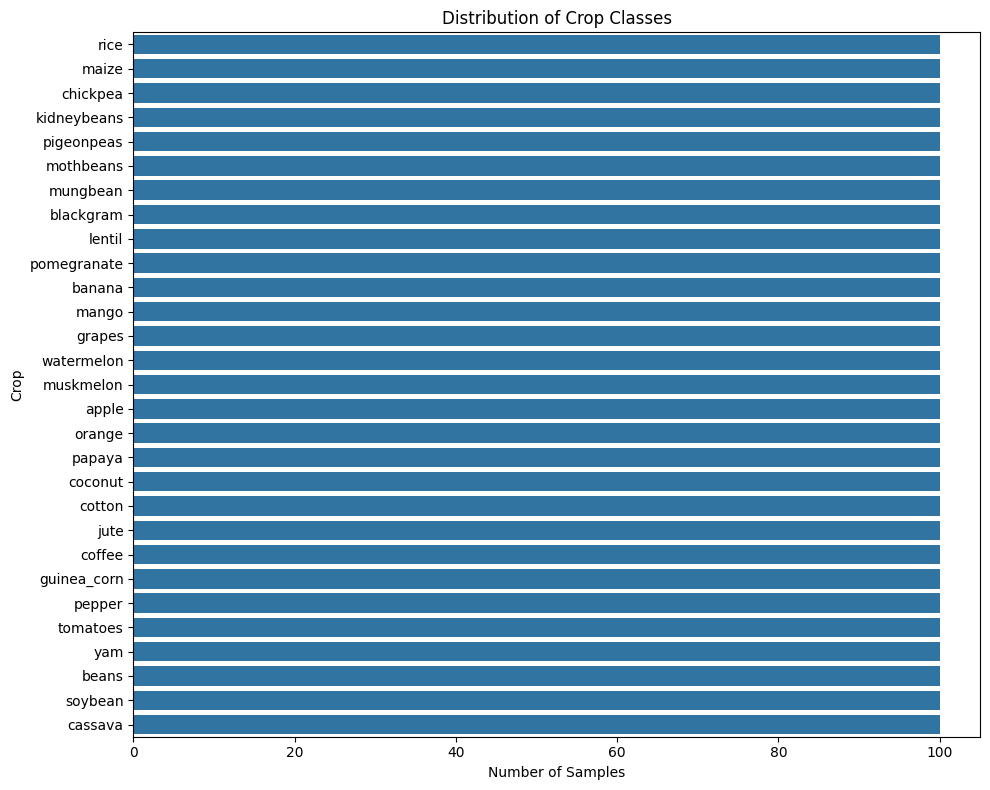

In [157]:
plt.figure(figsize=(10, 8))

sns.countplot(data=df, y="label", order=df["label"].value_counts().index)

plt.title("Distribution of Crop Classes")
plt.xlabel("Number of Samples")
plt.ylabel("Crop")
plt.tight_layout()
plt.show()

Graph 2: Histograms of numerical features


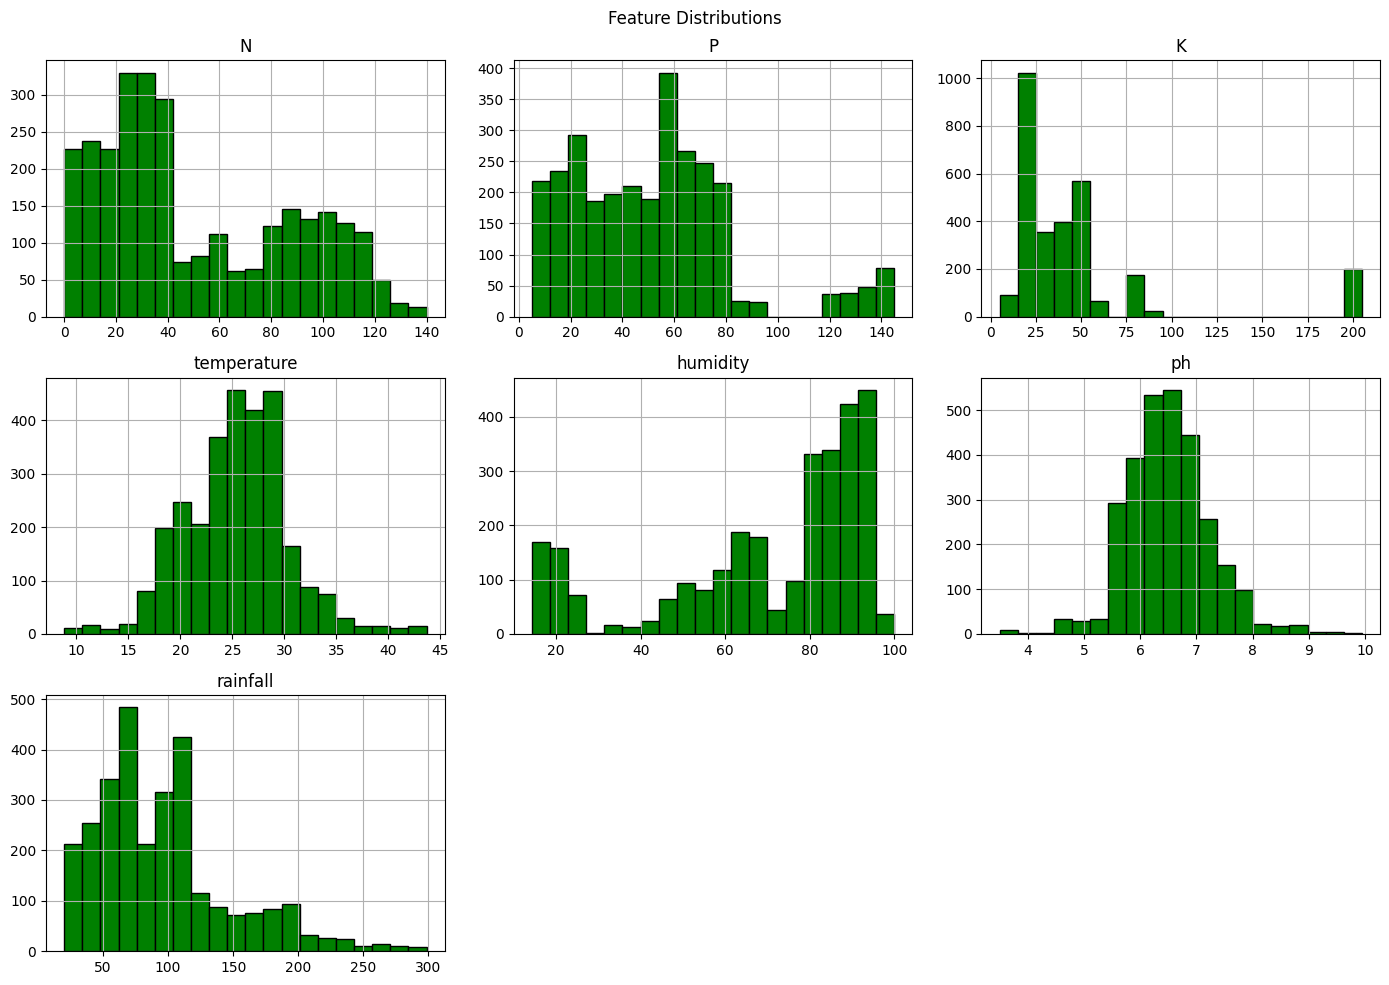

In [158]:
df.hist(figsize=(14, 10), bins=20, edgecolor="black", color="green")

plt.suptitle("Feature Distributions")
plt.tight_layout()
plt.show()

Graph 3: Correlation heatmap

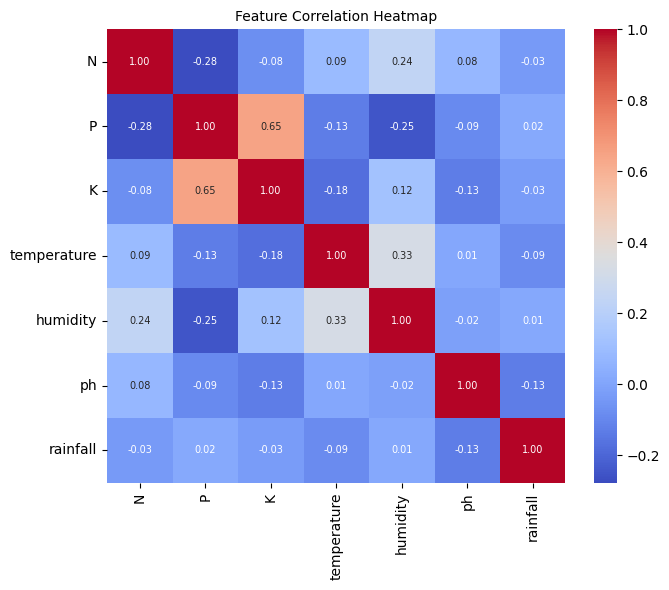

In [159]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(7, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    annot_kws={"size": 7}
)

plt.title("Feature Correlation Heatmap", fontsize=10)
plt.tight_layout()
plt.show()

Graph 4: Box plots for outliers

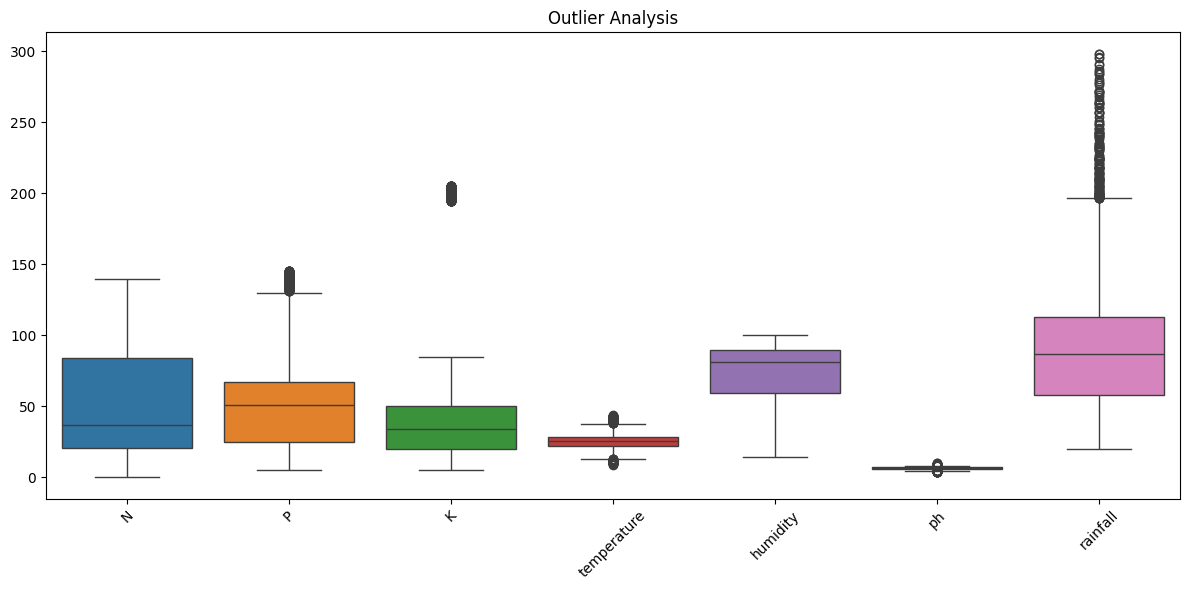

In [160]:
numeric_df = df.select_dtypes(include="number")

plt.figure(figsize=(12, 6))
sns.boxplot(data=numeric_df)
plt.xticks(rotation=45)
plt.title("Outlier Analysis")
plt.tight_layout()
plt.show()

Graph 5: Compare two features by crop

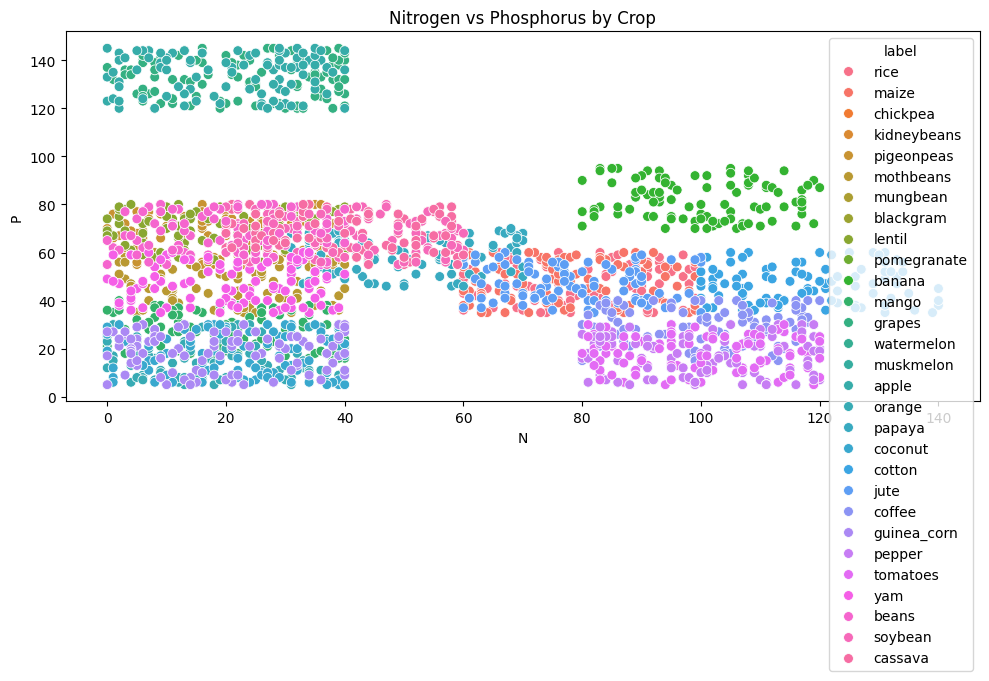

In [161]:
# N vs P
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="N",
    y="P",
    hue="label",
    s=50
)
plt.title("Nitrogen vs Phosphorus by Crop")
plt.tight_layout()
plt.show()

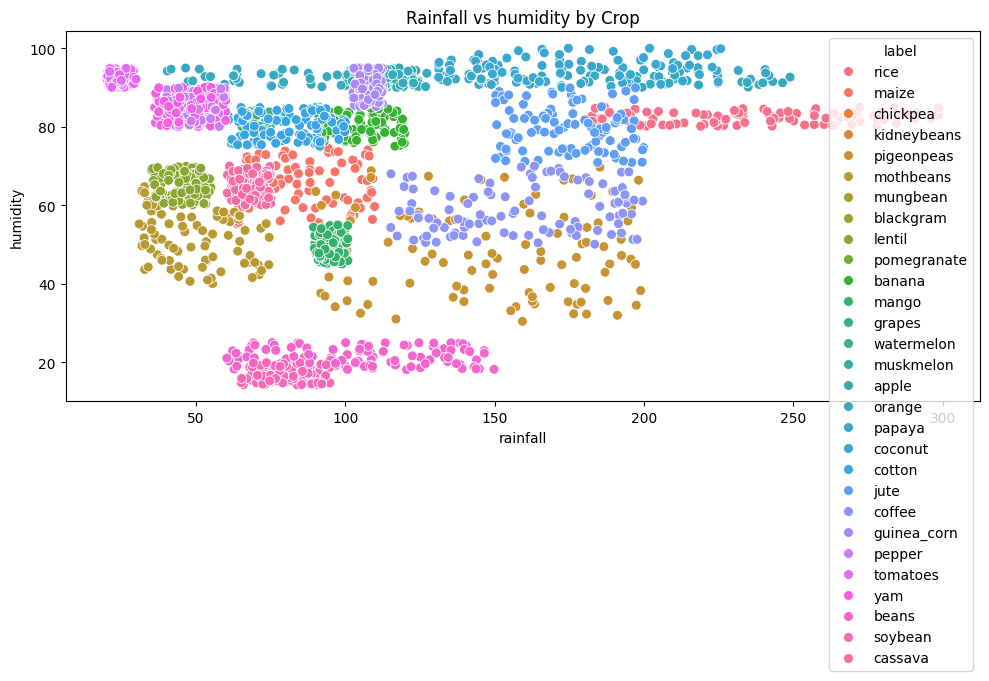

In [162]:
# Rainfall vs humidity
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="rainfall",
    y="humidity",
    hue="label",
    s=50
)
plt.title("Rainfall vs humidity by Crop")
plt.tight_layout()
plt.show()

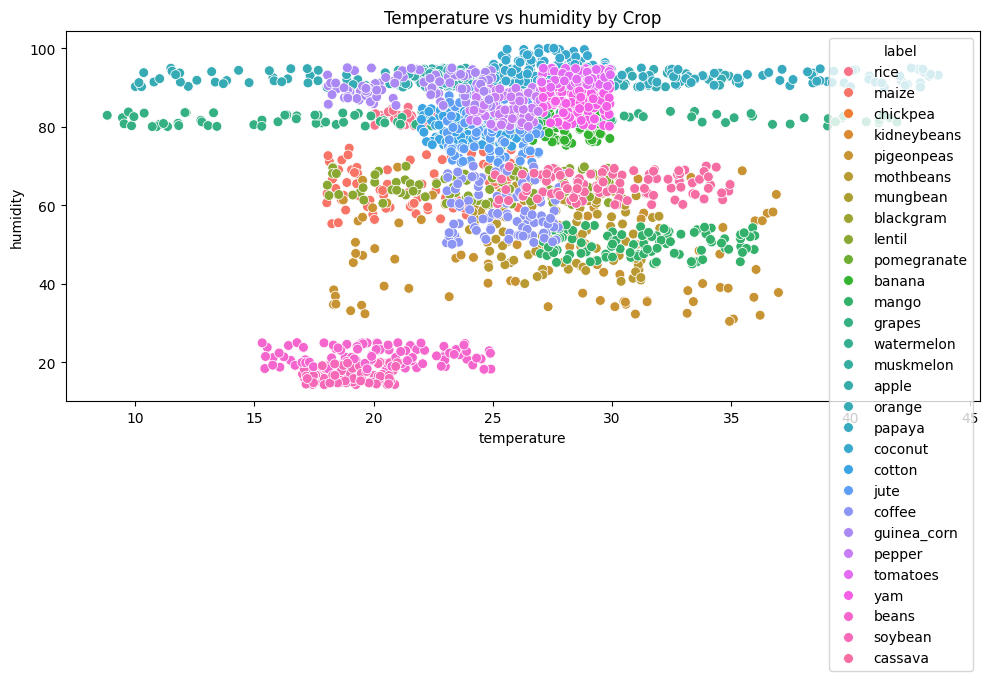

In [163]:
# Temperature vs humidity
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="temperature",
    y="humidity",
    hue="label",
    s=50
)
plt.title("Temperature vs humidity by Crop")
plt.tight_layout()
plt.show()

Graph 6: Rainfall distribution across crops

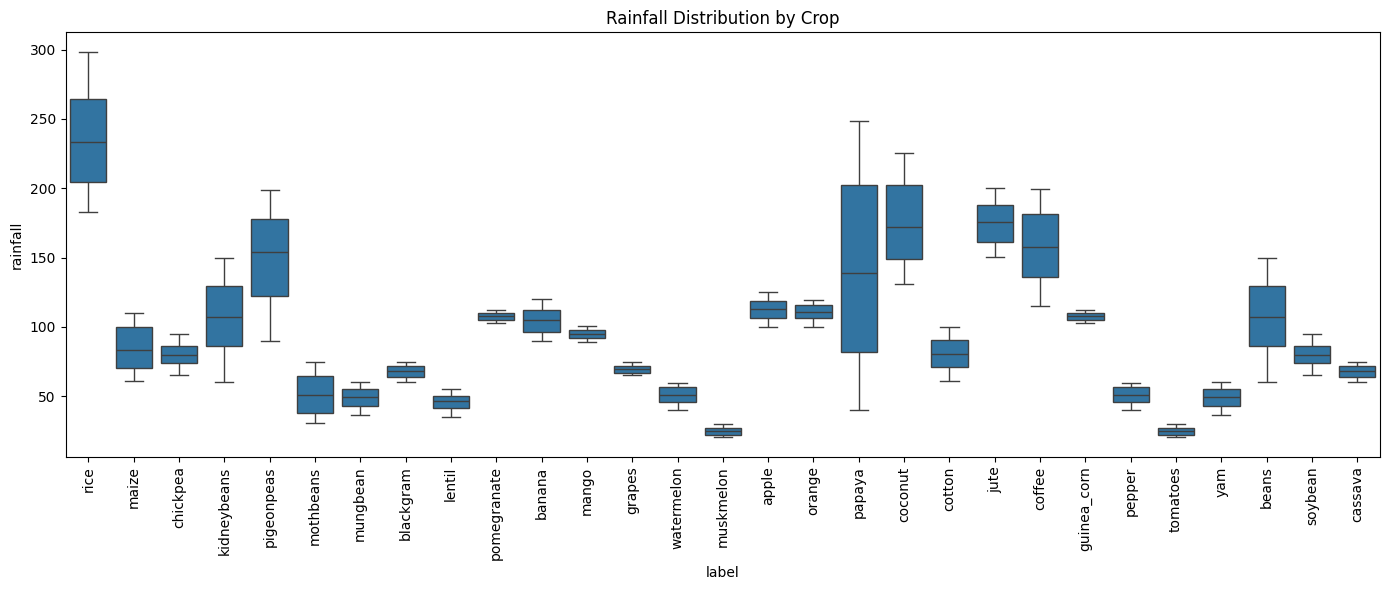

In [164]:
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=df,
    x="label",
    y="rainfall"
)
plt.xticks(rotation=90)
plt.title("Rainfall Distribution by Crop")
plt.tight_layout()
plt.show()

Graph 7: Features distribution accross crops

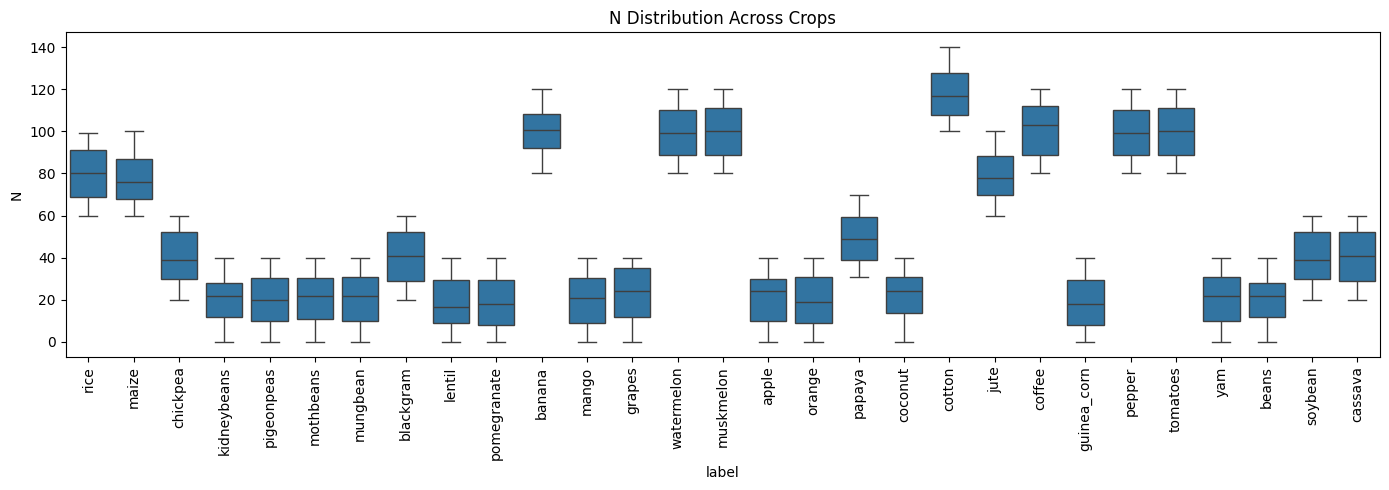

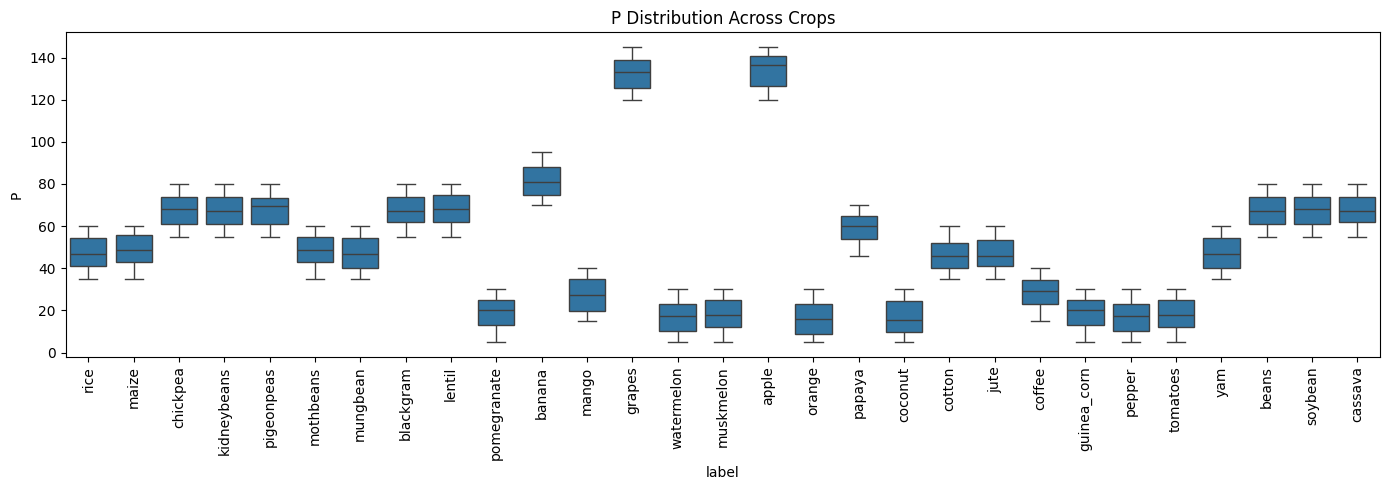

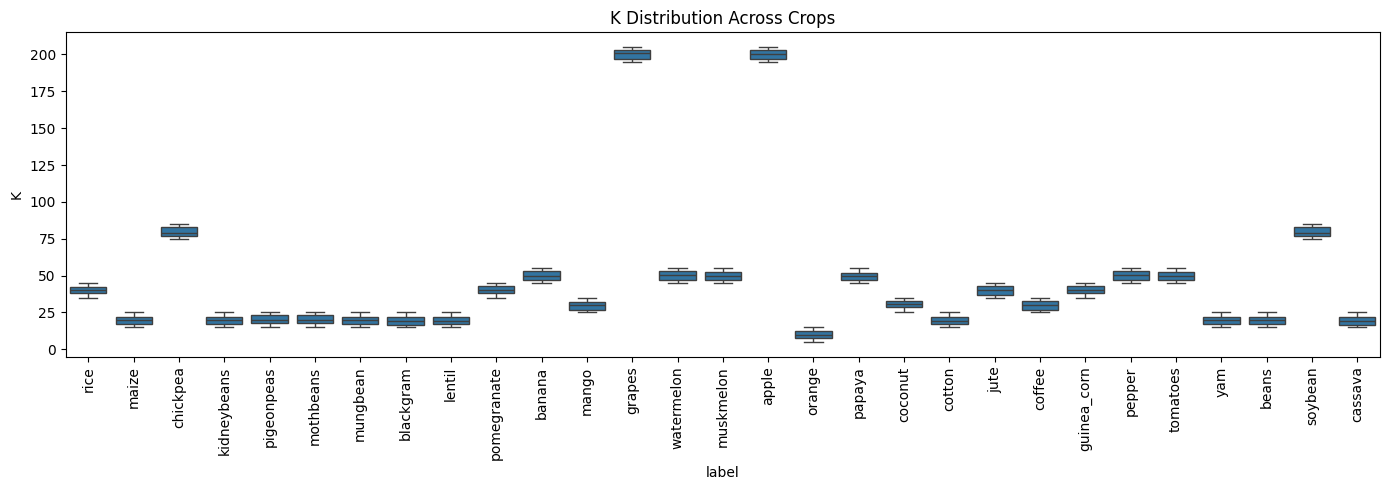

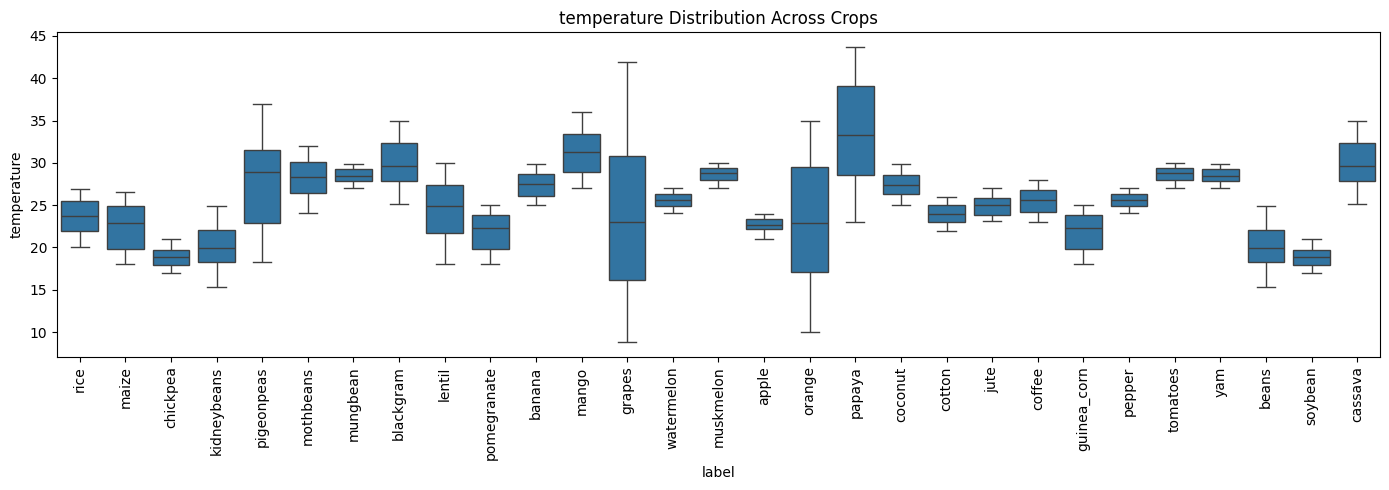

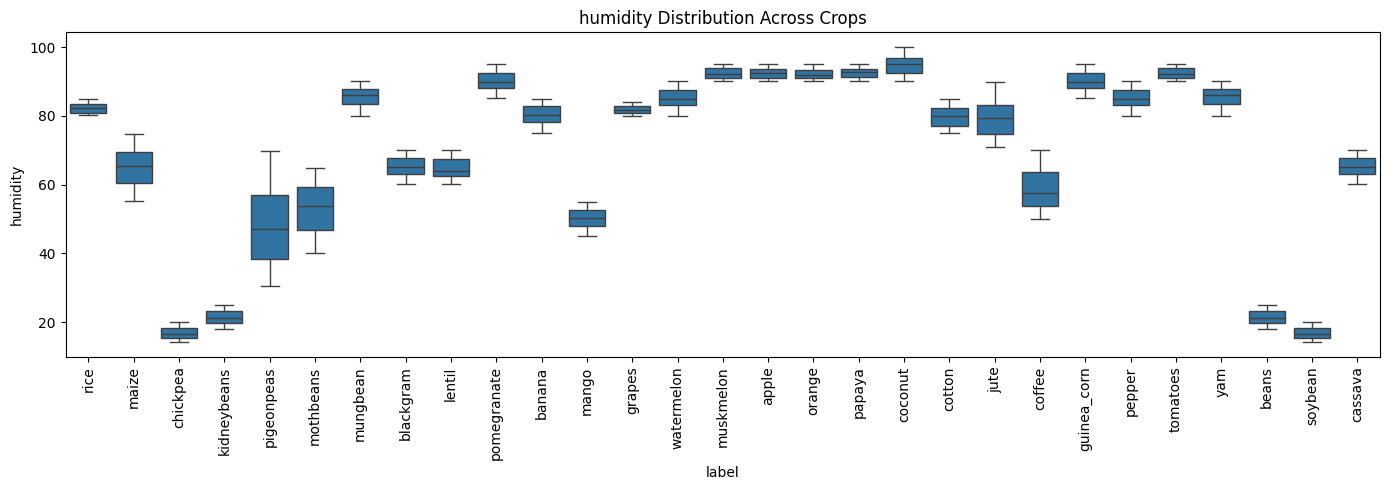

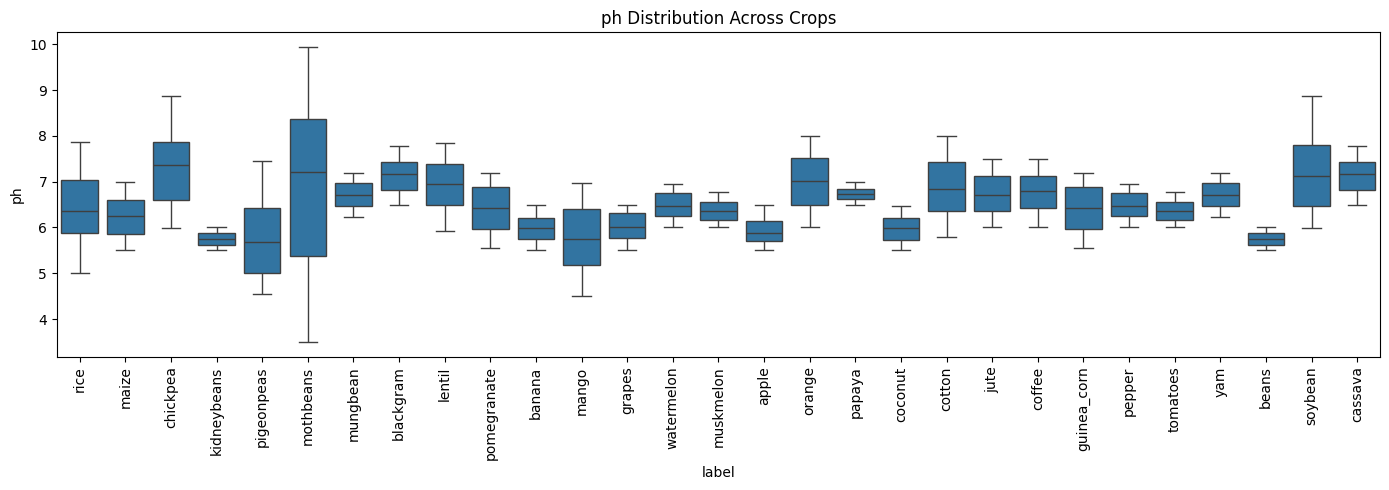

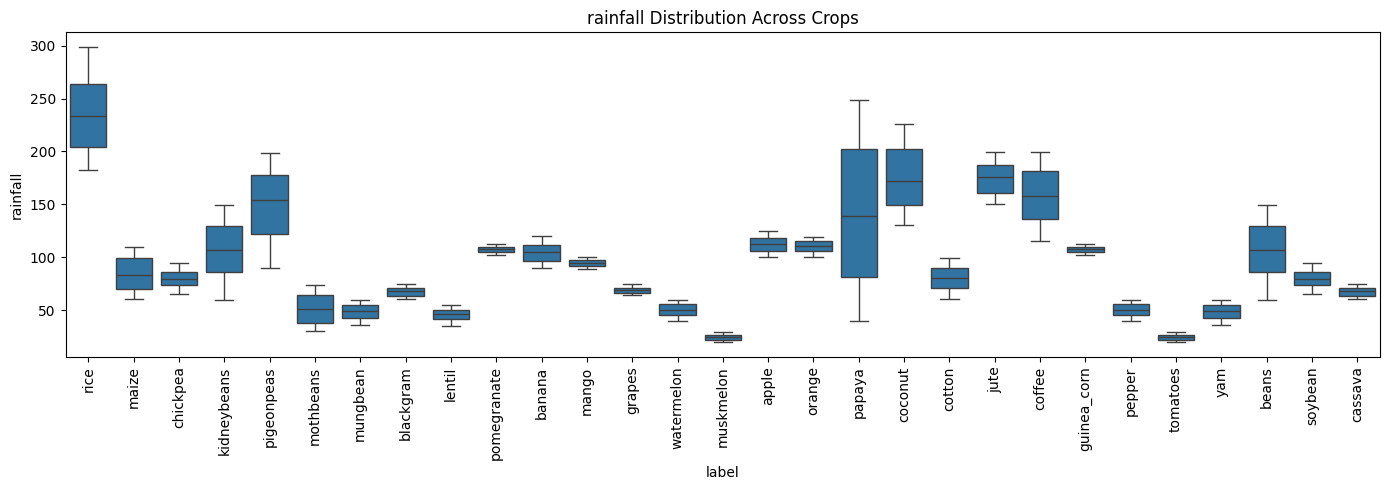

In [165]:
features = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]

for feature in features:
    plt.figure(figsize=(14, 5))

    sns.boxplot(data=df, x="label", y=feature)

    plt.xticks(rotation=90)
    plt.title(f"{feature} Distribution Across Crops")
    plt.tight_layout()
    plt.show()

### **Split And Save Train And Test Dataset**

**1. Separate Features and Target**

In [166]:
x = df.drop(columns=["label"])
y = df["label"]

print("Features:", x.columns.tolist())
print("Target:", y.name)

print("X shape:", x.shape)
print("y shape:", y.shape)

Features: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall']
Target: label
X shape: (2900, 7)
y shape: (2900,)


**2. Split the dataset**

In [167]:
from sklearn.model_selection import train_test_split

In [168]:
x_train,x_test,y_train,y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))

Training samples: 2320
Testing samples: 580


In [169]:
# Save features
x_train.to_csv("../dataset/splits/merged_splits/x_train.csv", index=False)
x_test.to_csv("../dataset/splits/merged_splits/x_test.csv", index=False)

# Save labels
y_train.to_csv("../dataset/splits/merged_splits/y_train.csv", index=False)
y_test.to_csv("../dataset/splits/merged_splits/y_test.csv", index=False)

print("Datasets saved successfully!")

Datasets saved successfully!


## **Model Training**

**1. Load Train and Test Dataset**

In [170]:
x_train = pd.read_csv("../dataset/splits/x_train.csv")
x_test = pd.read_csv("../dataset/splits/x_test.csv")

y_train = pd.read_csv("../dataset/splits/y_train.csv").squeeze("columns")
y_test = pd.read_csv("../dataset/splits/y_test.csv").squeeze("columns")

### Decision Tree Model - 1

In [171]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(x_train, y_train)
dt_predictions = dt_model.predict(x_test)

print(dt_predictions)

['maize' 'rice' 'soybean' 'cotton' 'beans' 'kidneybeans' 'cotton' 'cotton'
 'apple' 'mungbean' 'guinea_corn' 'mango' 'coconut' 'mango' 'soybean'
 'kidneybeans' 'mothbeans' 'yam' 'grapes' 'watermelon' 'coconut' 'yam'
 'mothbeans' 'pomegranate' 'beans' 'muskmelon' 'yam' 'mango' 'mungbean'
 'banana' 'kidneybeans' 'coffee' 'muskmelon' 'pepper' 'mothbeans'
 'blackgram' 'soybean' 'coffee' 'mothbeans' 'jute' 'mungbean' 'muskmelon'
 'lentil' 'soybean' 'yam' 'blackgram' 'apple' 'orange' 'watermelon'
 'pepper' 'coffee' 'chickpea' 'apple' 'grapes' 'mothbeans' 'cotton'
 'orange' 'jute' 'mothbeans' 'coffee' 'banana' 'coffee' 'soybean' 'rice'
 'watermelon' 'soybean' 'cassava' 'lentil' 'cotton' 'banana' 'mango'
 'coffee' 'beans' 'cotton' 'mothbeans' 'grapes' 'guinea_corn' 'chickpea'
 'coconut' 'jute' 'pomegranate' 'guinea_corn' 'yam' 'soybean' 'blackgram'
 'grapes' 'coconut' 'soybean' 'jute' 'pomegranate' 'mungbean' 'pepper'
 'yam' 'mungbean' 'orange' 'banana' 'cassava' 'mango' 'guinea_corn'
 'maize'

In [172]:
print("Decision Tree Accuracy:",
      accuracy_score(y_test, dt_predictions))

print(classification_report(y_test, dt_predictions))

Decision Tree Accuracy: 0.5637931034482758
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       0.95      1.00      0.98        20
       beans       0.14      0.15      0.15        20
   blackgram       0.23      0.30      0.26        20
     cassava       0.00      0.00      0.00        20
    chickpea       0.29      0.35      0.32        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
 guinea_corn       0.13      0.15      0.14        20
        jute       0.95      0.95      0.95        20
 kidneybeans       0.11      0.10      0.10        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00     

### Random Forest Model - 2

In [173]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)
rf_model.fit(x_train, y_train)

rf_predictions = rf_model.predict(x_test)

In [174]:
print("Random Forest Accuracy:",
      accuracy_score(y_test, rf_predictions))

print(classification_report(y_test, rf_predictions))

Random Forest Accuracy: 0.5672413793103448
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
       beans       0.06      0.05      0.05        20
   blackgram       0.15      0.15      0.15        20
     cassava       0.15      0.15      0.15        20
    chickpea       0.13      0.10      0.11        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
 guinea_corn       0.10      0.10      0.10        20
        jute       0.95      1.00      0.98        20
 kidneybeans       0.17      0.20      0.19        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00     

### XGBoost Model - 3

In [175]:
from xgboost import XGBClassifier
from sklearn.preprocessing import LabelEncoder

# Encode crop labels as integers for XGBoost
label_encoder = LabelEncoder()

y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

# Create model
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=6,
    learning_rate=0.1,
    random_state=42,
    eval_metric="mlogloss",
    n_jobs=-1
)

xgb_model.fit(x_train, y_train_encoded)
xgb_predictions_encoded = xgb_model.predict(x_test)

# Convert predictions back to crop names
xgb_predictions = label_encoder.inverse_transform(
    xgb_predictions_encoded.astype(int)
)

In [176]:
# Evaluate the XGBoost 
print("XGBoost Accuracy:",
      accuracy_score(y_test, xgb_predictions))
print(classification_report(y_test, xgb_predictions))

XGBoost Accuracy: 0.5689655172413793
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
       beans       0.06      0.05      0.05        20
   blackgram       0.11      0.10      0.11        20
     cassava       0.18      0.20      0.19        20
    chickpea       0.27      0.30      0.29        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
 guinea_corn       0.00      0.00      0.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       0.17      0.20      0.19        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00 

### Support Vector Machine (SVM) - 4

In [177]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report

svm_model = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf")
)
svm_model.fit(x_train, y_train)
svm_predictions = svm_model.predict(x_test)

print("SVM Accuracy:",
      accuracy_score(y_test, svm_predictions))

print(classification_report(y_test, svm_predictions))

SVM Accuracy: 0.7051724137931035
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
       beans       0.33      0.30      0.32        20
   blackgram       0.23      0.15      0.18        20
     cassava       0.37      0.50      0.43        20
    chickpea       0.60      0.60      0.60        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
 guinea_corn       0.45      0.50      0.48        20
        jute       0.87      1.00      0.93        20
 kidneybeans       0.36      0.40      0.38        20
      lentil       1.00      1.00      1.00        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00     

### K-Nearest Neighbors (KNN) - 5
- KNN predicts a crop based on the labels of the most similar training samples.

In [178]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(x_train, y_train)
knn_predictions = knn_model.predict(x_test)

print("KNN Accuracy:",
      accuracy_score(y_test, knn_predictions))

print(classification_report(y_test, knn_predictions))

KNN Accuracy: 0.6103448275862069
              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
       beans       0.11      0.10      0.11        20
   blackgram       0.29      0.30      0.29        20
     cassava       0.26      0.25      0.26        20
    chickpea       0.32      0.35      0.33        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
 guinea_corn       0.15      0.15      0.15        20
        jute       0.87      1.00      0.93        20
 kidneybeans       0.17      0.20      0.18        20
      lentil       1.00      0.95      0.97        20
       maize       1.00      1.00      1.00        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.95      1.00      0.98     

### Compare ALL 5 models

In [179]:
results = pd.DataFrame({
    "Model": [
        "Decision Tree",
        "Random Forest",
        "KNN",
        "XGBoost",
        "SVM"
    ],
    "Accuracy": [
        accuracy_score(y_test, dt_predictions) * 100,
        accuracy_score(y_test, rf_predictions) * 100,
        accuracy_score(y_test, knn_predictions) * 100,
        accuracy_score(y_test, svm_predictions) * 100,
        accuracy_score(y_test, xgb_predictions) * 100
    ]
})

results = results.sort_values(
    by="Accuracy",
    ascending=False
)

print(results)

           Model   Accuracy
3        XGBoost  70.517241
2            KNN  61.034483
4            SVM  56.896552
1  Random Forest  56.724138
0  Decision Tree  56.379310


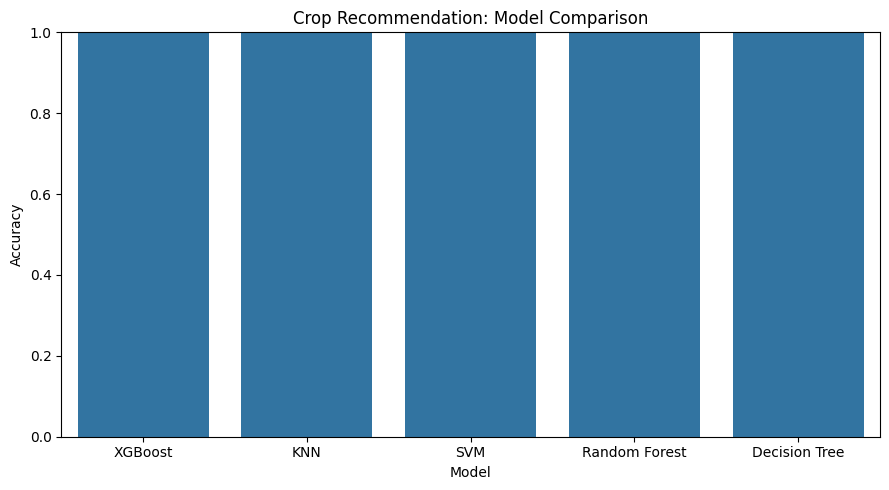

In [180]:

# Visualize the comparison:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=results,
    x="Model",
    y="Accuracy"
)

plt.title("Crop Recommendation: Model Comparison")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

### Save The Trained Model with High Accuracy

In [181]:
import joblib

# Save the trained model
joblib.dump(rf_model, "../models/merged_crop_model_rf.pkl")

['../models/merged_crop_model_rf.pkl']